# Landcover made practical: quick start to advanced workflows

**SWMMX 0.0.44 | merged notebooks 23 and 24**

The everyday workflow is **define classes → set coverage → preview → apply**. Start with the quick-start lesson, then use the linked topics when needed. Standalone previews need no model; model application is demonstrated after building a small SI network.

Use **Restart Kernel and Run All**. This notebook creates local synthetic inputs, checks numerical results, demonstrates expected errors, and runs two teaching simulations. No online data are required. All engineering values and rain are illustrative, not design recommendations. Outputs are written under landcover_044. Existing add_class/assign/derive/apply_hydrology examples remain as compatible advanced APIs; new work should prefer bulk input and reviewed previews.

## Contents

1. [Installation and environment check](#lesson-1)
2. [Separate subcatchments, landcover and native LANDUSES](#lesson-2)
3. [Quick start: define, cover, preview](#lesson-3)
4. [Units you must keep consistent](#lesson-4)
5. [Four equivalent coverage inputs](#lesson-5)
6. [Replacement and explicit normalization](#lesson-6)
7. [Class management and independent snapshots](#lesson-7)
8. [A reusable five-class SI library](#lesson-8)
9. [Bulk tables, CSV and complete row diagnostics](#lesson-9)
10. [Coverage inspection and table export](#lesson-10)
11. [Hand-check the hydrological formulas](#lesson-11)
12. [Missing properties versus absent surfaces](#lesson-12)
13. [Optional zero-storage percentage](#lesson-13)
14. [Infiltration: pervious weighting and dominant classes](#lesson-14)
15. [Advanced infiltration: custom rules and method compatibility](#lesson-15)
16. [Create a small SI SWMM model and attach the manager](#lesson-16)
17. [Preview and selectively apply native hydrology](#lesson-17)
18. [Safe stale-preview handling and workflow state](#lesson-18)
19. [Validation reports and summaries](#lesson-19)
20. [Explicit units at the SWMM boundary](#lesson-20)
21. [GIS foundations: subcatchments and surface polygons](#lesson-21)
22. [Overlay GeoDataFrames and verify areas](#lesson-22)
23. [Names-only presets and coverage-first maps](#lesson-23)
24. [GIS files and model polygon workflows](#lesson-24)
25. [CRS protection and explicit reprojection](#lesson-25)
26. [GIS errors: overlaps, gaps, labels and geometry](#lesson-26)
27. [Area reconciliation, GIS output and maps](#lesson-27)
28. [Stale spatial products after conversion](#lesson-28)
29. [Progress, cancellation and GIS rollback](#lesson-29)
30. [LID candidates and numerical checks](#lesson-30)
31. [Advanced suitability and user-defined filters](#lesson-31)
32. [Independent scenarios: convert area or whole-catchment fraction](#lesson-32)
33. [Compare scenarios and explore a conversion sweep](#lesson-33)
34. [Lightweight scenarios and explicit model cloning](#lesson-34)
35. [Update a used class in one operation](#lesson-35)
36. [Optimisation bounds without an optimiser](#lesson-36)
37. [Optional native water-quality conversion](#lesson-37)
38. [Standalone JSON persistence](#lesson-38)
39. [Save and reopen a model-sidecar pair](#lesson-39)
40. [Frontend-ready JSON contracts and stable identity](#lesson-40)
41. [Run SWMM and understand stale-result state](#lesson-41)
42. [Troubleshooting reference and validation examples](#lesson-42)
43. [Apply the workflow to your real urban project](#lesson-43)
44. [Practice exercises and executable solutions](#lesson-44)
45. [API reference and discovering help](#lesson-45)
46. [Final summary, generated files and further reading](#lesson-46)

<a id="lesson-1"></a>

## 1. Installation and environment check

Use Python 3.10+ and a Jupyter kernel with SWMMX installed. If dependencies are
missing, install them **in that same kernel**, then restart it. This command is
shown for guidance and is not automatically executed:

```python
%pip install swmmx numpy pandas matplotlib networkx geopandas shapely pyogrio
```

For a local release, replace `swmmx` with your wheel path. JupyterLab itself can
be installed using `pip install jupyterlab`. This complete guide needs the GIS
packages; standalone landcover calculations do not. The simulation lesson uses
the bundled native engine. The first cell supports a checkout or installed package.

In [1]:
from pathlib import Path
import importlib.util
import sys
repo = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/swmmx/landcover').is_dir()), None)
if repo is not None:
    sys.path.insert(0, str(repo/'src'))
required = ['swmmx','numpy','pandas','matplotlib','networkx','geopandas','shapely','pyogrio']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError('Install in this notebook kernel: '+', '.join(missing))
%matplotlib inline
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
from IPython.display import display
from swmmx import landcover, swmm, LandCover, SWMMXError, LandCoverValidationError, __version__
OUTPUT = (repo/'examples/output' if repo else Path.cwd())/'landcover_044'
OUTPUT.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_columns',14)
print('SWMMX:',__version__, 'Python:',sys.version.split()[0])
print('Outputs:',OUTPUT)

def explain_error(label, action):
    try:
        action()
    except SWMMXError as exc:
        print(f'{label}: {type(exc).__name__}: {exc}')
    else:
        raise AssertionError(f'{label}: expected a validation error')

SWMMX: 0.1.0 Python: 3.12.14
Outputs: C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\examples\output\landcover_044


<a id="lesson-2"></a>

## 2. Separate subcatchments, landcover and native LANDUSES

| Concept | Question | Example |
|---|---|---|
| Subcatchment | Which land drains to this outlet? | S1 drains to J1 |
| Landcover | What physical surfaces occupy this area? | Roof, road, green |
| Native LANDUSES | Which water-quality categories apply? | Pollutant buildup categories |

Landcover aggregates surface properties into SWMM's subcatchment/subarea model.
It does not create an independent runoff plane per class, delineate drainage
boundaries or size pipes. Use **reviewed subcatchments → surface intersection →
parameter preview → explicit application → simulation**.

Establish actual drainage connections first. One node need not have exactly one
subcatchment. The nearest node need not receive the runoff. Terrain, buried-pipe
levels, soil, rainfall and outfall conditions remain separate project inputs.

<a id="lesson-3"></a>

## 3. Quick start: define, cover, preview

Start with these three operations. A standalone project needs no SWMM model.
Declare SI property units, define classes together, and assign complete fractions.
`preview()` calculates values and diagnostics without changing anything. Once a
model is attached, `apply(preview)` is the fourth step. The model lesson demonstrates it.

Do not fill in advanced properties you do not need: choose
`preview(parameters=['imperviousness'])` if you only want impervious percentage.

In [2]:
simple = landcover(units='SI')
simple.define_classes({
    'roof': {'impervious':1, 'n_imp':.012, 'dstore_imp':1.5},
    'green': {'impervious':0, 'n_perv':.2, 'dstore_perv':5},
})
simple.set_coverage({'S1': {'roof':.4, 'green':.6}}, area_m2=10000)
review = simple.preview()
display(review.values)
print('Can apply to SWMM now?', review.can_apply)  # False: no attached model yet.
assert review.values.loc['S1','percent_impervious'] == 40
# A standalone warning is expected; calculation itself succeeded.
print(review.issues[0].message)

,percent_impervious,n_imperv,n_perv,dstore_imperv,dstore_perv
subcatchment,,,,,
S1,40.0,0.012,0.2,1.5,5.0


Can apply to SWMM now? False
Calculation is standalone; native application is unavailable


<a id="lesson-4"></a>

## 4. Units you must keep consistent

Declare `units='SI'` or `units='US'` when creating your library. Derivation uses
those declared units. An attached preview converts length/rate values into the
model's native units and explains the conversion; application uses those reviewed
values. Original class definitions are unchanged.

| Quantity | Convention |
|---|---|
| Coverage / impervious / suitability fractions | 0..1 |
| Native imperviousness and pct_zero | 0..100 percent |
| Coverage/LID area | Always m² |
| Native model area | SI hectares / US acres |
| Class depression storage | SI mm / US inches |
| Infiltration conductivity | SI mm/hr / US inches/hr |
| Infiltration dry_time / decay / deficit | Model-specific time/dimensionless units; unchanged |

Legacy `landcover()` retains `units='native'`, assuming values match the model.
Prefer explicit units in new projects. Existing saved units cannot be overridden
silently when reopening. Area units on set_coverage are independent of class units.

<a id="lesson-5"></a>

## 5. Four equivalent coverage inputs

`units` describes the composition values. Standalone area input needs an
explicit total area; the manager never assumes the mapped part is the whole
catchment. These four assignments must give the same fractions.

In [3]:
units_demo = landcover()
units_demo.add_class('roof',impervious=1)
units_demo.add_class('green',impervious=0)
for sid, values, units in [
 ('fraction',{'roof':.4,'green':.6},'fraction'),
 ('percent',{'roof':40,'green':60},'percent'),
 ('m2',{'roof':4000,'green':6000},'m2'),
 ('ha',{'roof':.4,'green':.6},'ha')]:
    units_demo.assign(sid,values,units=units,area_m2=10000)
display(units_demo.coverage_table())
assert np.allclose(units_demo.coverage_table()['roof'],.4)
explain_error('Missing total area',lambda: units_demo.assign('unknown',{'roof':100},units='m2'))

,roof,green
subcatchment,,
fraction,0.4,0.6
percent,0.4,0.6
m2,0.4,0.6
ha,0.4,0.6


Missing total area: ValidationError: Standalone area assignment requires total area_m2


<a id="lesson-6"></a>

## 6. Replacement and explicit normalization

Use `overwrite=True` to replace an existing assignment. Incomplete totals
are rejected unless normalization is explicitly requested. Normalization only
rescales values; it does not identify missing land or justify ignoring it.
Individual fractions must still lie in 0..1 before normalization.

In [4]:
explain_error('Duplicate',lambda: simple.assign('S1',{'roof':1}))
explain_error('Incomplete',lambda: units_demo.assign('incomplete',{'roof':.2,'green':.3}))
units_demo.assign('rescaled',{'roof':.2,'green':.3},normalize=True,area_m2=10000)
units_demo.normalize('rescaled')
assert units_demo.coverage_fraction('rescaled','roof') == .4
units_demo.assign('rescaled',{'roof':.3,'green':.7},overwrite=True,area_m2=10000)
display(units_demo.coverage_table().loc[['rescaled']])

Duplicate: DuplicateIDError: S1 already assigned; use overwrite=True
Incomplete: ValidationError: incomplete: coverage sums to 0.5; expected 1; use normalize=True explicitly


,roof,green
subcatchment,,
rescaled,0.3,0.7


<a id="lesson-7"></a>

## 7. Class management and independent snapshots

`classes` and `get_class()` return snapshots. Use `update_class()` to change
properties safely and `rename_class()` to change labels. Stable class IDs survive
both operations; coverage references and JSON links stay consistent. Removal
still refuses referenced classes. All edits can be reviewed through metadata history.

In [5]:
manage = simple.copy()
manage.add_class('unused',impervious=.3,attributes={'cost_factor':1.2},description='Teaching metadata')
print(manage.list_classes(),manage.has_class('unused'))
snapshot = manage.get_class('unused')
snapshot.attributes['cost_factor'] = 9
assert manage.classes['unused'].attributes['cost_factor'] == 1.2
manage.remove_class('unused')
manage.rename_class('roof','building_roof')
assert manage.coverage_fraction('S1','building_roof') == .4
explain_error('Referenced class',lambda: manage.remove_class('building_roof'))
display(manage.classes_dataframe())
class_identity = manage.class_id('building_roof')
manage.update_class('building_roof', n_imp=.014)
assert manage.class_id('building_roof') == class_identity
assert manage.classes['building_roof'].n_imp == .014
manage.undo()
assert manage.classes['building_roof'].n_imp == .012
manage.redo()
display(pd.DataFrame(manage.history()))

['roof', 'green', 'unused'] True
Referenced class: ValidationError: building_roof is referenced by coverage or GIS data


,name,impervious,n_imp,n_perv,dstore_imp,dstore_perv,pct_zero,infiltration,lids,attributes,description
0,building_roof,1,0.012,NaN,1.5,NaN,None,None,{},{},None
1,green,0,NaN,0.2,NaN,5.0,None,None,{},{},None


,operation
0,add_class
1,remove_class
2,rename_class
3,update_class


<a id="lesson-8"></a>

## 8. A reusable five-class SI library

The helper creates independent managers for later lessons. `pedestrian` is
partly impervious and needs both property sets. Infiltration metadata describes
the pervious portion. Suitability describes eligible area, not installed controls.
`pct_zero` is a percentage of the class's impervious portion.
All values are illustrative; replace them with locally justified data.

In [6]:
def green_ampt(suction, conductivity, deficit):
    return {'model':'GREEN_AMPT','suction_head':suction,
            'hydraulic_conductivity':conductivity,'initial_moisture_deficit':deficit}

def urban_library(model=None):
    obj = landcover(model, units="SI")
    obj.add_class('roof',impervious=1,n_imp=.012,dstore_imp=1.5,pct_zero=70,
        lids={'green_roof':.7,'rain_barrel':1},attributes={'source':'teaching example'})
    obj.add_class('road',impervious=1,n_imp=.013,dstore_imp=2,pct_zero=20,
        lids={'permeable_pavement':.25,'bioretention':.1})
    obj.add_class('pedestrian',impervious=.8,n_imp=.015,n_perv=.15,dstore_imp=2,dstore_perv=4,
        pct_zero=30,infiltration=green_ampt(90,8,.2),lids={'permeable_pavement':.4})
    obj.add_class('green',impervious=0,n_perv=.2,dstore_perv=5,
        infiltration=green_ampt(110,12,.25),lids={'bioretention':.4,'swale':.5})
    obj.add_class('other',impervious=.3,n_imp=.015,n_perv=.18,dstore_imp=2,dstore_perv=5,
        pct_zero=10,infiltration=green_ampt(80,6,.15))
    return obj

baseline = urban_library()
composition = {'roof':.30,'road':.25,'pedestrian':.10,'green':.25,'other':.10}
baseline.assign('S1',composition,area_m2=10000)
baseline.assign('S2',{'roof':.2,'road':.2,'pedestrian':.1,'green':.4,'other':.1},area_m2=10000)
baseline.assign('S3',{'roof':.1,'road':.2,'pedestrian':.2,'green':.4,'other':.1},area_m2=10000)
baseline.classes_dataframe()

,name,impervious,n_imp,n_perv,dstore_imp,dstore_perv,pct_zero,infiltration,lids,attributes,description
0,roof,1.0,0.012,NaN,1.5,NaN,70.0,None,"{'green_roof': 0.7, 'rain_barrel': 1}",{'source': 'teaching example'},None
1,road,1.0,0.013,NaN,2.0,NaN,20.0,None,"{'permeable_pavement': 0.25, 'bioretention': 0.1}",{},None
2,pedestrian,0.8,0.015,0.15,2.0,4.0,30.0,"{'model': 'GREEN_AMPT', 'suction_head': 90, 'h...",{'permeable_pavement': 0.4},{},None
3,green,0.0,NaN,0.20,NaN,5.0,NaN,"{'model': 'GREEN_AMPT', 'suction_head': 110, '...","{'bioretention': 0.4, 'swale': 0.5}",{},None
4,other,0.3,0.015,0.18,2.0,5.0,10.0,"{'model': 'GREEN_AMPT', 'suction_head': 80, 'h...",{},{},None


<a id="lesson-9"></a>

## 9. Bulk tables, CSV and complete row diagnostics

Use mappings, DataFrames or CSV paths. Wide coverage has subcatchment and
class columns, plus optional area_m2. Long coverage has subcatchment, class (or
stable class_id), and exactly one of fraction/percent/area_m2/area_ha. Area-based
long rows may carry total_area_m2. Duplicate rows are errors, not silently summed.
`validate_only=True` returns all detected row issues without changing data.
Otherwise invalid batches raise LandCoverValidationError with `.report` and make
no partial changes. CSV cells for lids/infiltration/attributes contain JSON.

In [7]:
bulk = landcover(units='SI')
bulk.define_classes(pd.DataFrame([
    {'name':'roof','impervious':1}, {'name':'green','impervious':0}]))
long_cover = pd.DataFrame([
    {'subcatchment':'A','class':'roof','percent':40,'total_area_m2':1000},
    {'subcatchment':'A','class':'green','percent':60,'total_area_m2':1000}])
long_cover.to_csv(OUTPUT/'bulk_cover.csv',index=False)
bulk.set_coverage(OUTPUT/'bulk_cover.csv')
report = bulk.define_classes([{'name':'bad1','impervious':2},{'name':'bad2','n_imp':0}],validate_only=True)
assert len(report.issues)==2 and not bulk.has_class('bad1')
display(report.to_dataframe())
display(bulk.preview(['imperviousness']).values)

,code,severity,object_id,field,message,remedy,row
0,INVALID_INPUT,error,bad1,classes,"impervious must be finite and in [0, 1]",Correct the indicated record and resubmit the ...,0
1,INVALID_INPUT,error,bad2,classes,"n_imp must be finite and in [0, inf] and positive",Correct the indicated record and resubmit the ...,1


,percent_impervious
subcatchment,
A,40.0


<a id="lesson-10"></a>

## 10. Coverage inspection and table export

`coverage()` returns a structured snapshot; `coverage_table()` returns fractions.
`to_dataframe()` combines area, coverage, hydrology and LID bounds, so it requires
enough properties and area information for those calculations.

In [8]:
display(baseline.coverage_table())
print('Roof area:',baseline.coverage_area('S1','roof'),'m²')
print('Fraction:',baseline.coverage_fraction('S1','roof'))
print('Dominant class:',baseline.dominant_class('S1'))
print(baseline.coverage('S1'))
baseline.coverage_table().to_csv(OUTPUT/'coverage_fractions.csv')
baseline.classes_dataframe().to_json(OUTPUT/'classes_table.json',orient='records',indent=2)
baseline.to_dataframe().round(4)

,roof,road,pedestrian,green,other
subcatchment,,,,,
S1,0.3,0.25,0.1,0.25,0.1
S2,0.2,0.20,0.1,0.40,0.1
S3,0.1,0.20,0.2,0.40,0.1


Roof area: 3000.0 m²
Fraction: 0.3
Dominant class: roof
LandCoverCoverage(subcatchment='S1', fractions={'roof': 0.3, 'road': 0.25, 'pedestrian': 0.1, 'green': 0.25, 'other': 0.1}, area_m2=10000.0)


,area_m2,roof_fraction,road_fraction,pedestrian_fraction,green_fraction,other_fraction,roof_area_m2,...,dstore_imperv,dstore_perv,lid_bioretention_area_m2,lid_green_roof_area_m2,lid_permeable_pavement_area_m2,lid_rain_barrel_area_m2,lid_swale_area_m2
subcatchment,,,,,,,,,,,,,,,
S1,10000.0,0.3,0.25,0.1,0.25,0.1,3000.0,...,1.7727,4.9412,1250.0,2100.0,1025.0,3000.0,1250.0
S2,10000.0,0.2,0.20,0.1,0.40,0.1,2000.0,...,1.8039,4.9592,1800.0,1400.0,900.0,2000.0,2000.0
S3,10000.0,0.1,0.20,0.2,0.40,0.1,1000.0,...,1.8980,4.9216,1800.0,700.0,1300.0,1000.0,2000.0


<a id="lesson-11"></a>

## 11. Hand-check the hydrological formulas

For class fraction $f_i$ and impervious fraction $I_i$:

$$\%Imperv=100\sum_i f_i I_i$$
$$N_{imp}=\frac{\sum_i f_i I_i n_{imp,i}}{\sum_i f_i I_i},\quad
N_{perv}=\frac{\sum_i f_i(1-I_i)n_{perv,i}}{\sum_i f_i(1-I_i)}$$

Storage uses the corresponding surface weights. These are effective-parameter
approximations, not exact separate-surface simulations. S1 has imperviousness
0.30 + 0.25 + 0.10×0.80 + 0.10×0.30 = 0.66.

In [9]:
hydro = baseline.derive_hydrology()
expected = {
 'percent_impervious':66,
 'n_imperv':(.30*.012+.25*.013+.08*.015+.03*.015)/.66,
 'n_perv':(.02*.15+.25*.20+.07*.18)/.34,
 'dstore_imperv':(.30*1.5+.25*2+.08*2+.03*2)/.66,
 'dstore_perv':(.02*4+.25*5+.07*5)/.34}
for key,value in expected.items():
    assert np.isclose(hydro.loc['S1',key],value)
display(pd.DataFrame({'calculated':hydro.loc['S1'],'hand_checked':pd.Series(expected)}))

,calculated,hand_checked
percent_impervious,66.000000,66.000000
n_imperv,0.012879,0.012879
n_perv,0.192941,0.192941
dstore_imperv,1.772727,1.772727
dstore_perv,4.941176,4.941176


<a id="lesson-12"></a>

## 12. Missing properties versus absent surfaces

Missing properties of a contributing surface raise errors. A zero-area surface
returns NaN for its effective parameters; application preserves its existing
native values. Do not substitute zero for missing roughness. If only imperviousness
is needed, request only that calculation.

In [10]:
partial = landcover()
partial.add_class('roof',impervious=1)
partial.assign('S',{'roof':1})
explain_error('Missing roughness',lambda: partial.derive_hydrology())
display(partial.derive_hydrology(roughness=False,depression_storage=False))
only_roof = baseline.copy()
only_roof.assign('S1',{'roof':1},overwrite=True,area_m2=10000)
row = only_roof.derive_hydrology().loc['S1']
assert pd.isna(row.n_perv) and pd.isna(row.dstore_perv)
display(row.to_frame('fully_impervious_example'))

Missing roughness: ValidationError: S: class roof needs n_imp


,percent_impervious
subcatchment,
S,100.0


,fully_impervious_example
percent_impervious,100.000
n_imperv,0.012
n_perv,NaN
dstore_imperv,1.500
dstore_perv,NaN


<a id="lesson-13"></a>

## 13. Optional zero-storage percentage

`pct_zero=True` requests impervious-area-weighted class percentages. This is
not a percentage of the whole catchment. Every contributing impervious class
must supply the property.

In [11]:
with_zero = baseline.derive_hydrology(pct_zero=True)
assert np.isclose(with_zero.loc['S1','pct_zero'],(.30*70+.25*20+.08*30+.03*10)/.66)
with_zero.round(4)

,percent_impervious,n_imperv,n_perv,dstore_imperv,dstore_perv,pct_zero
subcatchment,,,,,,
S1,66.0,0.0129,0.1929,1.7727,4.9412,43.4848
S2,51.0,0.0130,0.1951,1.8039,4.9592,40.5882
S3,49.0,0.0136,0.1933,1.8980,4.9216,32.8571


<a id="lesson-14"></a>

## 14. Infiltration: pervious weighting and dominant classes

SWMM uses one native infiltration parameter set for a subcatchment's pervious
part. `area_weighted` uses pervious weights; `dominant` selects the largest
pervious contribution. Neither exactly reproduces arbitrary heterogeneous soils.
The calculation below excludes roofs and roads because they are fully impervious.

In [12]:
weighted_inf = baseline.derive_infiltration(method='area_weighted')
dominant_inf = baseline.derive_infiltration(method='dominant')
assert np.isclose(weighted_inf.loc['S1','hydraulic_conductivity'],(.02*8+.25*12+.07*6)/.34)
assert dominant_inf.loc['S1','hydraulic_conductivity'] == 12
display(weighted_inf)
display(dominant_inf)

,model,suction_head,hydraulic_conductivity,initial_moisture_deficit
subcatchment,,,,
S1,GREEN_AMPT,102.647059,10.529412,0.226471
S2,GREEN_AMPT,104.897959,10.979592,0.233673
S3,GREEN_AMPT,104.313725,10.862745,0.232353


,model,suction_head,hydraulic_conductivity,initial_moisture_deficit
subcatchment,,,,
S1,GREEN_AMPT,110,12,0.25
S2,GREEN_AMPT,110,12,0.25
S3,GREEN_AMPT,110,12,0.25


<a id="lesson-15"></a>

## 15. Advanced infiltration: custom rules and method compatibility

A callback receives parts containing class, weight, model and parameters, and
returns a complete parameter dictionary. This example selects the lowest-
conductivity class. It demonstrates the callback contract, **not a universal
conservative design rule**.

Supported model tokens: HORTON, MODIFIED_HORTON, GREEN_AMPT,
MODIFIED_GREEN_AMPT and CURVE_NUMBER. Built-in aggregation rejects mixed models.
An attached model must match the resulting method. Custom conversion rules need
independent scientific justification.

In [13]:
def choose_lowest_conductivity(parts):
    chosen = min(parts,key=lambda p:p['hydraulic_conductivity'])
    return {key:chosen[key] for key in ['model','suction_head','hydraulic_conductivity','initial_moisture_deficit']}
custom_inf = baseline.derive_infiltration(method='custom',function=choose_lowest_conductivity)
assert custom_inf.loc['S1','hydraulic_conductivity'] == 6
display(custom_inf)
mixed = baseline.copy()
mixed.add_class('cn_soil',impervious=0,infiltration={'model':'CURVE_NUMBER','curve_number':80,'conductivity':0,'dry_time':3})
mixed.convert('S1','green','cn_soil',fraction=.1)
explain_error('Mixed methods',lambda: mixed.derive_infiltration())

,model,suction_head,hydraulic_conductivity,initial_moisture_deficit
subcatchment,,,,
S1,GREEN_AMPT,80,6,0.15
S2,GREEN_AMPT,80,6,0.15
S3,GREEN_AMPT,80,6,0.15


Mixed methods: ValidationError: S1: incompatible infiltration models {'GREEN_AMPT', 'CURVE_NUMBER'}


<a id="lesson-16"></a>

## 16. Create a small SI SWMM model and attach the manager

We build three one-hectare catchments, three junctions and an outfall using
explicit teaching elevations, sizes, slope, width, rainfall and infiltration.
Coordinates are synthetic projected coordinates, not a surveyed city.

`attach()` checks IDs and total areas. A model has one attached manager;
`landcover(m)` returns that manager. This example avoids external sample files.

In [14]:
CRS = 'EPSG:32639'
sub_polygons = [box(500000+i*100,4000000,500100+i*100,4000100) for i in range(3)]
subcatchments = gpd.GeoDataFrame({'subcatchment':['S1','S2','S3']},geometry=sub_polygons,crs=CRS)
m = swmm(new='SI',flow_unit='CMS')
m.options['INFILTRATION'] = 'GREEN_AMPT'
for key in ['START_DATE','END_DATE','REPORT_START_DATE']:
    m.options[key] = '01/01/2026'
m.options['START_TIME'] = '00:00:00'
m.options['REPORT_START_TIME'] = '00:00:00'
m.options['END_TIME'] = '03:00:00'
m.options['REPORT_STEP'] = '00:05:00'
m.options['FLOW_ROUTING'] = 'DYNWAVE'
m.add.time.time_series('Rain',data=[('2026-01-01 00:00',0),('2026-01-01 00:05',15),
    ('2026-01-01 00:10',30),('2026-01-01 00:15',15),('2026-01-01 00:20',0)])
m.add.hydrology.rain_gage('RG',format='INTENSITY',interval='00:05',source_type='TIMESERIES',time_series='Rain')
for i in range(3):
    m.add.node.junction(f'J{i+1}',x=500050+i*100,y=4000000,invert_elevation=99-i,max_depth=3)
m.add.node.outfall('OUT',x=500350,y=4000000,invert_elevation=96)
for i in range(3):
    m.add.link.conduit(f'C{i+1}',from_node=f'J{i+1}',to_node=f'J{i+2}' if i<2 else 'OUT',
                       length=100,diameter=.6,roughness=.013)
for i,polygon in enumerate(sub_polygons):
    m.add.hydrology.subcatchment(f'S{i+1}',rain_gage='RG',outlet=f'J{i+1}',
        x=polygon.centroid.x,y=polygon.centroid.y,area=1,width=100,slope=1,
        polygon=list(polygon.exterior.coords),suction_head=110,hydraulic_conductivity=12,
        initial_moisture_deficit=.25)
attached = baseline.copy()
attached.attach(m)
assert landcover(m) is attached
assert attached.coverage_area('S1','roof') == 3000
assert m.validate().ok
pd.DataFrame(m.section('SUBCATCHMENTS'),columns=['id','gage','outlet','area_ha','impervious_pct','width_m','slope_pct','curb_m'])

,id,gage,outlet,area_ha,impervious_pct,width_m,slope_pct,curb_m
0,S1,RG,J1,1.0,0.0,100.0,1.0,0.0
1,S2,RG,J2,1.0,0.0,100.0,1.0,0.0
2,S3,RG,J3,1.0,0.0,100.0,1.0,0.0


<a id="lesson-17"></a>

## 17. Preview and selectively apply native hydrology

Review before applying. A preview contains independent `.values` and
`.changes` tables, structured `.issues`, `.assumptions` and `.can_apply`.
It remembers the project revision and complete native-model fingerprint.
Any later edit makes it stale, even an edit that is subsequently undone.
Native application is atomic and uses existing validated SWMM setters.
The legacy `apply_hydrology()` delegates to this same preview/adapter workflow.

In [15]:
before_subareas = m.section('SUBAREAS')
before_imp = m.get.subcatchment.impervious_percent(ids='S1')
p = attached.preview(parameters=['imperviousness'])
display(p.changes)
assert p.can_apply and m.get.subcatchment.impervious_percent(ids='S1') == before_imp
attached.apply(p)
assert m.section('SUBAREAS') == before_subareas
assert m.get.subcatchment.impervious_percent(ids='S1') == 66
full_review = attached.preview(['imperviousness','roughness','depression_storage','pct_zero','infiltration'])
display(full_review.changes.head(8))
print(full_review.assumptions)
attached.apply(full_review)
assert attached.status['model_updated']
print(attached.status)

,subcatchment,parameter,current,proposed,unit
0,S1,percent_impervious,0.0,66.0,%
1,S2,percent_impervious,0.0,51.0,%
2,S3,percent_impervious,0.0,49.0,%


,subcatchment,parameter,current,proposed,unit
0,S1,percent_impervious,66.0,66.0,%
1,S1,n_imperv,0.01,0.012879,Manning n
2,S1,n_perv,0.1,0.192941,Manning n
3,S1,dstore_imperv,0.05,1.772727,mm
4,S1,dstore_perv,0.05,4.941176,mm
5,S1,pct_zero,25.0,43.484848,%
6,S1,model,GREEN_AMPT,GREEN_AMPT,model-specific
7,S1,suction_head,110.0,102.647059,model-specific


['Class length/rate units: SI; preview target units: SI.', 'Impervious/pervious properties use their respective area weights; effective parameter approximation.', 'Absent surfaces produce null parameters and preserve native values on application.', 'Infiltration aggregation: area_weighted; a pervious-area approximation.']
{'project_id': '43590f53-7de3-423f-974c-607d0dcb6569', 'revision': 1, 'coverage_ready': True, 'preview_ready': False, 'model_updated': True, 'spatial_state': 'not_loaded', 'spatial_message': 'No GIS products; import surfaces and calculate coverage', 'can_undo': False, 'can_redo': False}


<a id="lesson-18"></a>

## 18. Safe stale-preview handling and workflow state

Inspect state rather than guessing what has been applied. Revisions increase
on successful metadata edits and undo/redo. History holds up to 20 in-memory
metadata transactions; application to SWMM is excluded. Native model edits are
fingerprinted too. Preview handles are local to the originating manager/session.

In [16]:
review = attached.preview(['imperviousness'])
attached.update_class('roof',description='Reviewed teaching roof')
explain_error('Stale review',lambda: attached.apply(review))
attached.undo()
explain_error('Undo does not revive old reviews',lambda: attached.apply(review))
attached.apply(attached.preview(['imperviousness']))
assert attached.status['model_updated']
display(pd.Series(attached.status))

Stale review: ValidationError: Stale preview: project or model changed; generate and review a new preview
Undo does not revive old reviews: ValidationError: Stale preview: project or model changed; generate and review a new preview


project_id                      43590f53-7de3-423f-974c-607d0dcb6569
revision                                                           3
coverage_ready                                                  True
preview_ready                                                  False
model_updated                                                   True
spatial_state                                             not_loaded
spatial_message    No GIS products; import surfaces and calculate...
can_undo                                                       False
can_redo                                                        True
dtype: object

<a id="lesson-19"></a>

## 19. Validation reports and summaries

`lc.validate()` checks metadata/derivation and reports unassigned model
catchments. `m.validate()` performs structural model checks. Neither certifies
engineering adequacy. `summary()` reports assigned area and area-weighted
imperviousness. Record uncertain assumptions even when validation passes.

In [17]:
display(attached.validate())
display(m.validate().to_frame())
summary = attached.summary()
display(pd.Series({k:v for k,v in summary.items() if k not in ['source','validation']}))
assert attached.validate().empty

,severity,subcatchment,message


,severity,code,message,section,object_id
0,warning,RESULTS_NOT_AVAILABLE,Run-dependent results are not available until ...,None,None


classes                        5.000000
assigned_subcatchments         3.000000
assigned_area_m2           30000.000000
mean_percent_impervious       55.333333
dtype: float64

<a id="lesson-20"></a>

## 20. Explicit units at the SWMM boundary

This separate small US model illustrates class-property conversion only;
it is not a conversion of an existing SI network. Classes are declared in SI,
while preview/application convert storage and infiltration lengths/rates to US.
Time, fractions and Manning coefficients are unchanged. Derived standalone
values and class definitions remain in the declared source units.

In [18]:
us = swmm(new='US')
us.options['INFILTRATION']='GREEN_AMPT'
us.add.time.time_series('Dry',data=[('2026-01-01 00:00',0)])
us.add.hydrology.rain_gage('R',format='INTENSITY',interval='00:05',source_type='TIMESERIES',time_series='Dry')
us.add.node.outfall('O',x=0,y=0,invert_elevation=0)
us.add.hydrology.subcatchment('A',rain_gage='R',outlet='O',x=0,y=10,area=1,width=100,slope=1,
    suction_head=1,hydraulic_conductivity=1,initial_moisture_deficit=.2)
unit_demo=landcover(us,units='SI')
unit_demo.define_classes({'roof':{'impervious':1,'n_imp':.012,'dstore_imp':25.4}})
unit_demo.set_coverage({'A':{'roof':1}})
unit_review=unit_demo.preview()
assert np.isclose(unit_review.values.loc['A','dstore_imperv'],1)
unit_demo.apply(unit_review)
assert np.isclose(us.get.subcatchment.depression_storage_impervious(ids='A'),1)
assert unit_demo.classes['roof'].dstore_imp==25.4
print(unit_review.assumptions[0])

Class length/rate units: SI; preview target units: US.

<a id="lesson-21"></a>

## 21. GIS foundations: subcatchments and surface polygons

Use two layers with known CRS. The synthetic catchments are 100 × 100 m.
Each surface polygon has a class matching the library. Repeated class names are
expected; GIS row indices must be unique. These stripes illustrate known fractions,
not a method for delineating actual urban drainage boundaries.

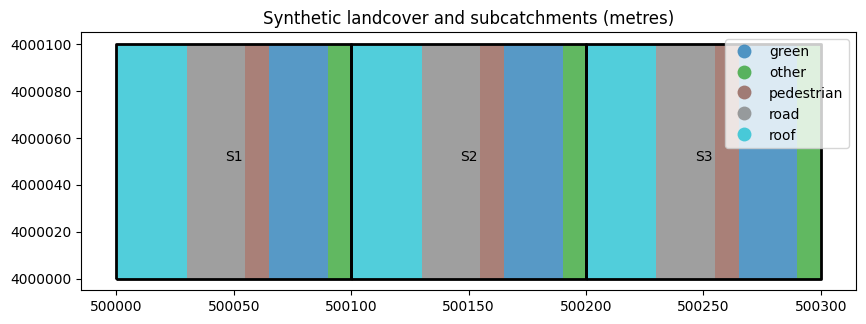

In [19]:
surface_records = []
for i in range(3):
    x = 500000+i*100
    for name,left,right in [('roof',0,30),('road',30,55),('pedestrian',55,65),('green',65,90),('other',90,100)]:
        surface_records.append({'class':name,'geometry':box(x+left,4000000,x+right,4000100)})
surfaces = gpd.GeoDataFrame(surface_records,crs=CRS)
assert surfaces.geometry.is_valid.all()
fig,ax = plt.subplots(figsize=(10,4))
surfaces.plot(column='class',legend=True,ax=ax,alpha=.75)
subcatchments.boundary.plot(ax=ax,color='black',linewidth=2)
for row in subcatchments.itertuples():
    ax.text(row.geometry.centroid.x,row.geometry.centroid.y,row.subcatchment,ha='center')
ax.set_title('Synthetic landcover and subcatchments (metres)')
ax.ticklabel_format(style='plain',useOffset=False)
plt.show()

<a id="lesson-22"></a>

## 22. Overlay GeoDataFrames and verify areas

`overlay(landcover=..., subcatchments=...)` works without an attached model.
It requires complete coverage and rejects overlapping source polygons. Inspect
both aggregated fractions and detailed intersection areas. Missing areas are not
automatically assigned to 'other'; resolve them explicitly upstream.

In [20]:
spatial = urban_library()
spatial.overlay(landcover=surfaces,subcatchments=subcatchments)
assert np.allclose(spatial.coverage_table().sum(axis=1),1)
assert np.isclose(spatial.intersections_geodataframe().area_m2.sum(),30000)
assert spatial.coverage_fraction('S1','roof') == .3
display(spatial.coverage_table())
display(spatial.intersections_geodataframe().head())
display(spatial.to_geodataframe(include_hydrology=True)[['subcatchment','area_m2','roof_fraction','percent_impervious']])

,roof,road,pedestrian,green,other
subcatchment,,,,,
S1,0.3,0.25,0.1,0.25,0.1
S2,0.3,0.25,0.1,0.25,0.1
S3,0.3,0.25,0.1,0.25,0.1


,subcatchment,landcover,area_m2,fraction,geometry
0,S1,roof,3000.0,0.30,"POLYGON ((500030 4000100, 500030 4000000, 5000..."
1,S1,road,2500.0,0.25,"POLYGON ((500055 4000100, 500055 4000000, 5000..."
2,S1,pedestrian,1000.0,0.10,"POLYGON ((500065 4000100, 500065 4000000, 5000..."
3,S1,green,2500.0,0.25,"POLYGON ((500090 4000100, 500090 4000000, 5000..."
4,S1,other,1000.0,0.10,"POLYGON ((500100 4000000, 500090 4000000, 5000..."


,subcatchment,area_m2,roof_fraction,percent_impervious
0,S1,10000.0,0.3,66.0
1,S2,10000.0,0.3,66.0
2,S3,10000.0,0.3,66.0


<a id="lesson-23"></a>

## 23. Names-only presets and coverage-first maps

The urban starter creates familiar labels but invents no engineering values.
You can map composition before collecting hydrological parameters. Request only
the calculations you are ready to support. GIS still requires reviewed boundaries,
known CRS, no overlaps and complete coverage.

,subcatchment,roof_fraction,green_fraction
0,S1,0.3,0.25
1,S2,0.3,0.25
2,S3,0.3,0.25


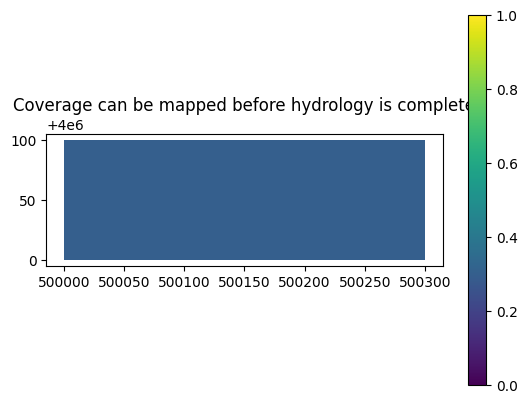

Missing-property issues: 16


In [21]:
starter = landcover(units='SI',preset='urban')
assert starter.classes['roof'].impervious is None
starter.set_surfaces(surfaces)
starter.calculate_coverage(subcatchments=subcatchments)
display(starter.coverage_geodataframe()[['subcatchment','roof_fraction','green_fraction']])
assert 'percent_impervious' not in starter.coverage_geodataframe()
starter.plot(class_name='roof',vmin=0,vmax=1,legend=True)
plt.title('Coverage can be mapped before hydrology is complete'); plt.show()
issues = starter.preview(['imperviousness']).issues
assert any(i.code=='MISSING_PROPERTY' for i in issues)
print('Missing-property issues:',len(issues))

<a id="lesson-24"></a>

## 24. GIS files and model polygon workflows

GeoPandas supports formats such as GeoPackage, Shapefile and GeoJSON. Here we
write and read synthetic local files. `layer` selects the GeoPackage layer.
When using attached model polygons instead of an explicit subcatchment layer,
supply `model_crs`: INP has no reliable standard CRS field. Existing coverage
needs explicit overwrite.

In [22]:
surface_file = OUTPUT/'teaching_surfaces.gpkg'
surfaces.to_file(surface_file,layer='surfaces',driver='GPKG',mode='w')
subcatchments.to_file(OUTPUT/'teaching_subcatchments.geojson',driver='GeoJSON')
file_workflow = urban_library()
file_workflow.from_gis(surface_file,class_field='class',layer='surfaces')
file_workflow.overlay(subcatchments=subcatchments)
pd.testing.assert_frame_equal(spatial.coverage_table(),file_workflow.coverage_table())
model_gis = attached.copy()
model_gis.set_surfaces(surfaces,class_column='class')
model_gis.calculate_coverage(model_crs=CRS,overwrite=True)
assert np.allclose(model_gis.coverage_table().sum(axis=1),1)
display(pd.Series(file_workflow.source))

class_field                                                    class
original_crs                                              EPSG:32639
source_file        C:\Users\Mohammadali\Documents\My_Codes\swmmx_...
source_layer                                                surfaces
area_crs                                                  EPSG:32639
polygon_area_m2        {'S1': 10000.0, 'S2': 10000.0, 'S3': 10000.0}
area_basis         polygon fractions; attached model area for cov...
dtype: object

<a id="lesson-25"></a>

## 25. CRS protection and explicit reprojection

Geographic degrees are not usable area units. Both inputs need a known CRS.
Geographic or mismatched inputs require an explicit projected `area_crs`.
Choose a projection suitable for your region; projected feet are converted to m².
`set_crs` labels coordinates; `to_crs` transforms them. Never relabel longitude/
latitude as metres.

In [23]:
geo_surfaces = surfaces.to_crs('EPSG:4326')
geo_subs = subcatchments.to_crs('EPSG:4326')
explain_error('Geographic area',lambda: urban_library().overlay(geo_surfaces,geo_subs))
explain_error('Different CRS',lambda: urban_library().overlay(geo_surfaces,subcatchments))
reprojected = urban_library()
reprojected.overlay(geo_surfaces,geo_subs,area_crs=CRS)
assert np.isclose(reprojected.coverage_area('S1','roof'),3000,atol=.001)
print('Recovered roof area:',reprojected.coverage_area('S1','roof'),'m²')

Geographic area: ValidationError: Area requires a projected CRS; provide area_crs
Different CRS: ValidationError: Mismatched CRS; choose explicit area_crs to reproject
Recovered roof area: 2999.9999999342253 m²


<a id="lesson-26"></a>

## 26. GIS errors: overlaps, gaps, labels and geometry

Resolve geometry errors explicitly. Do not hide them by rescaling fractions.
Outside polygons contribute nothing; positive slivers are retained. Valid
MultiPolygon geometry is supported. Repeated class labels are allowed, whereas
duplicate source indices are rejected. The following examples must fail clearly.

In [24]:
overlap = surfaces.copy()
overlap.loc[0,'geometry'] = box(500000,4000000,500040,4000100)
explain_error('Overlap',lambda: urban_library().overlay(overlap,subcatchments))
gap = surfaces.drop(index=0)
explain_error('Uncovered area',lambda: urban_library().overlay(gap,subcatchments))
unknown = surfaces.copy()
unknown.loc[0,'class'] = 'undefined'
explain_error('Unknown class',lambda: urban_library().from_geodataframe(unknown))
empty = surfaces.copy()
empty.loc[0,'geometry'] = None
explain_error('Missing geometry',lambda: urban_library().from_geodataframe(empty))
duplicate = surfaces.copy()
duplicate.index = [0]*len(duplicate)
explain_error('Duplicate index',lambda: urban_library().from_geodataframe(duplicate))

Overlap: ValidationError: Overlapping landcover polygons at rows 0, 1
Uncovered area: ValidationError: S1: coverage sums to 0.7; expected 1; use normalize=True explicitly


Unknown class: ValidationError: Unknown land-cover class: undefined
Missing geometry: ValidationError: Invalid, missing or empty geometry; repair it explicitly before import
Duplicate index: ValidationError: Duplicate GIS index IDs; provide unique IDs


<a id="lesson-27"></a>

## 27. Area reconciliation, GIS output and maps

Coverage GeoDataFrames and maps now work without complete hydrological
properties. Use `include_hydrology=True` / `include_lids=True` for optional joined
results. Attached fractions use polygon intersections; physical coverage/LID areas
use SWMM area. Reconcile both totals rather than assuming they agree.

,subcatchment,polygon_area_m2,model_area_m2,difference_m2
0,S1,10000.0,10000.0,0.0
1,S2,10000.0,10000.0,0.0
2,S3,10000.0,10000.0,0.0


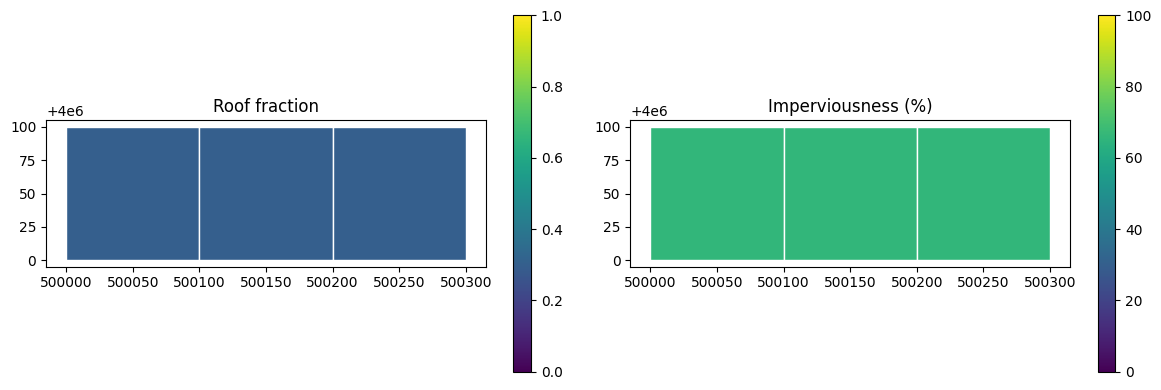

In [25]:
area_audit = subcatchments[['subcatchment']].copy()
area_audit['polygon_area_m2'] = subcatchments.area
area_audit['model_area_m2'] = [m.get.subcatchment.area(ids=s)*10000 for s in area_audit.subcatchment]
area_audit['difference_m2'] = area_audit.model_area_m2-area_audit.polygon_area_m2
assert np.allclose(area_audit.difference_m2,0)
display(area_audit)
model_gis.to_geodataframe().to_file(OUTPUT/'landcover_results.gpkg',layer='subcatchments',driver='GPKG',mode='w')
model_gis.intersections_geodataframe().to_file(OUTPUT/'landcover_intersections.geojson',driver='GeoJSON')
fig,axes = plt.subplots(1,2,figsize=(12,4))
model_gis.plot(class_name='roof',ax=axes[0],legend=True,vmin=0,vmax=1,edgecolor='white')
model_gis.plot(kind='imperviousness',ax=axes[1],legend=True,vmin=0,vmax=100,edgecolor='white')
axes[0].set_title('Roof fraction'); axes[1].set_title('Imperviousness (%)')
plt.tight_layout(); plt.show()

<a id="lesson-28"></a>

## 28. Stale spatial products after conversion

Importing surfaces or changing coverage invalidates cached intersections.
Changes to attached model polygon rows are also detected. Aggregate conversion
does not specify where new polygons should lie. Use scenario tables, or supply
revised GIS polygons before making a new scenario map.

In [26]:
spatial_change = model_gis.copy()
spatial_change.convert('S1','road','green',area=100)
explain_error('Stale intersections',lambda: spatial_change.intersections_geodataframe())
assert len(model_gis.intersections_geodataframe()) == 15

Stale intersections: ValidationError: No current intersections; run overlay() after importing or changing coverage


<a id="lesson-29"></a>

## 29. Progress, cancellation and GIS rollback

A progress callback receives stage/completed/total dictionaries; cancelled()
can cooperatively stop the operation. Checks run between stages and during overlap
checks. The GEOS intersection call itself is not interruptible, so cancellation
may wait for it to return. Callbacks should observe progress, not edit the project.
No partial coverage is saved after cancellation or callback failure.

In [27]:
events=[]
job=urban_library()
job.set_surfaces(surfaces)
before=job.to_project().to_json()
explain_error('Cancelled overlay',lambda: job.calculate_coverage(subcatchments=subcatchments,
    progress=events.append,cancelled=lambda: len(events)>=3))
assert before==job.to_project().to_json()
job.calculate_coverage(subcatchments=subcatchments,progress=events.append)
display(pd.DataFrame(events).drop_duplicates())

Cancelled overlay: LandCoverCancelled: GIS operation cancelled; metadata unchanged


,stage,completed,total
0,validate_inputs,0,5
1,validate_overlap,1,5
2,intersect,2,5
6,aggregate,3,5
7,assign,4,5
10,ready_to_commit,5,5


<a id="lesson-30"></a>

## 30. LID candidates and numerical checks

Candidate area for type $l$ is $A_s\sum_i f_i u_{i,l}$. Roof suitability 0.7
means 70% of roof area is eligible, not that a control was created or structural
suitability confirmed. Different technologies may compete for the same land.
Never sum their bounds as if they were jointly available. Rain-barrel candidate
area is associated screening area, not barrel count or storage volume.

,subcatchment,lid_type,candidate_area_m2,candidate_fraction
0,S1,bioretention,1250.0,0.1250
1,S1,green_roof,2100.0,0.2100
2,S1,permeable_pavement,1025.0,0.1025
3,S1,rain_barrel,3000.0,0.3000
4,S1,swale,1250.0,0.1250
5,S2,bioretention,1800.0,0.1800
6,S2,green_roof,1400.0,0.1400
7,S2,permeable_pavement,900.0,0.0900
8,S2,rain_barrel,2000.0,0.2000
9,S2,swale,2000.0,0.2000


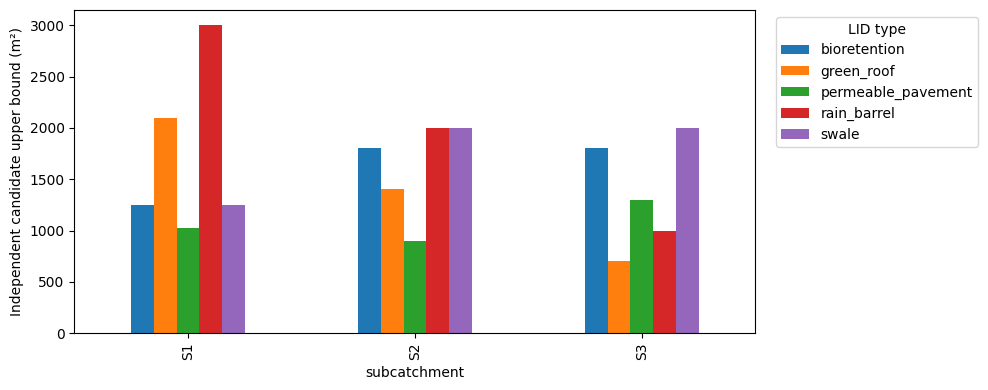

In [28]:
candidates = baseline.lid_candidates()
first = baseline.lid_candidates('S1').set_index('lid_type')
assert np.isclose(first.loc['green_roof','candidate_area_m2'],10000*.3*.7)
assert np.isclose(first.loc['bioretention','candidate_area_m2'],10000*(.25*.1+.25*.4))
display(candidates.head(10))
candidates.pivot(index='subcatchment',columns='lid_type',values='candidate_area_m2').plot.bar(figsize=(10,4))
plt.ylabel('Independent candidate upper bound (m²)')
plt.legend(title='LID type',bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout(); plt.show()

<a id="lesson-31"></a>

## 31. Advanced suitability and user-defined filters

Rich metadata supports suitable_fraction, min_area in m², and priority.
Here min_area applies to each **aggregate class contribution**, not individual
polygons. Priority is descriptive; no optimiser acts on it automatically.
A callback may reduce the candidate area but cannot increase it. The example
halves the bound as an explicit hypothetical ownership constraint.

In [29]:
rich = landcover()
rich.add_class('parking',impervious=1,lids={'bioretention':{'suitable_fraction':.2,'min_area':50,'priority':.8}})
rich.assign('small',{'parking':1},area_m2=100)
rich.assign('large',{'parking':1},area_m2=1000)
display(rich.lid_candidates())
assert rich.lid_candidates('small').candidate_area_m2.iloc[0] == 0
filtered = baseline.lid_candidates(filter_function=lambda row:row['candidate_area_m2']*.5)
assert np.allclose(filtered.candidate_area_m2,candidates.candidate_area_m2*.5)
explain_error('Filter increases bound',lambda: baseline.lid_candidates(filter_function=lambda row:row['candidate_area_m2']+1))

,subcatchment,lid_type,candidate_area_m2,candidate_fraction
0,small,bioretention,0.0,0.0
1,large,bioretention,200.0,0.2


Filter increases bound: ValidationError: filtered candidate area must be finite and in [0, 1250.0]


<a id="lesson-32"></a>

## 32. Independent scenarios: convert area or whole-catchment fraction

`copy()` duplicates metadata and clones an attached model. `convert()` accepts
exactly one of area (m2/ha) or fraction. Fraction means a share of the **whole
subcatchment**, not the source class. Conversion preserves total coverage and
rejects overdraw. Native parameters change only on explicit application.

In [30]:
future = attached.copy()
original_native = m.get.subcatchment.impervious_percent(ids='S1')
future.convert('S1',source='road',target='green',area=500,units='m2')
assert attached.coverage_fraction('S1','road') == .25
assert np.isclose(future.coverage_fraction('S1','road'),.20)
assert future.model.get.subcatchment.impervious_percent(ids='S1') == original_native
future.apply_hydrology(infiltration=True)
assert np.isclose(future.model.get.subcatchment.impervious_percent(ids='S1'),61)
assert m.get.subcatchment.impervious_percent(ids='S1') == 66
explain_error('Source overdraw',lambda: future.convert('S1','road','green',fraction=.9))
fraction_scenario = attached.copy()
fraction_scenario.convert('S1','road','green',fraction=.05)
pd.testing.assert_frame_equal(future.coverage_table(),fraction_scenario.coverage_table())

Source overdraw: ValidationError: Conversion exceeds available source coverage


<a id="lesson-33"></a>

## 33. Compare scenarios and explore a conversion sweep

`baseline.compare(future)` returns future minus baseline. Assigned IDs and
total areas must match. New classes/LID types align to zero; absent-surface
hydrology may remain NaN. The sweep below explores derived parameters without
repeatedly running SWMM.

,road_area_m2,green_area_m2,percent_impervious,n_imperv,n_perv
subcatchment,,,,,
S1,-500.0,500.0,-5.0,-0.00001,0.000905


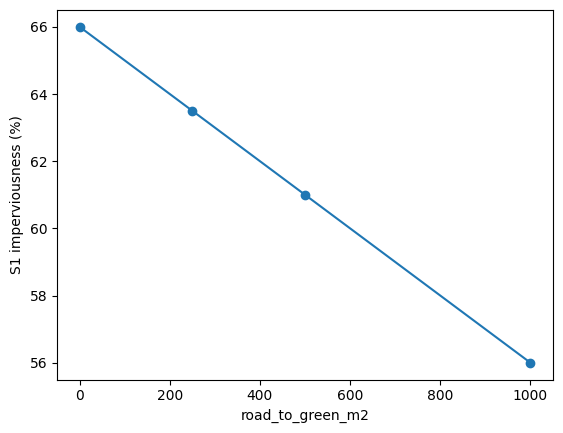

,road_to_green_m2,impervious_percent
0,0,66.0
1,250,63.5
2,500,61.0
3,1000,56.0


In [31]:
delta = attached.compare(future)
display(delta.loc[['S1'],['road_area_m2','green_area_m2','percent_impervious','n_imperv','n_perv']])
assert np.isclose(delta.loc['S1','percent_impervious'],-5)
rows = []
for area in [0,250,500,1000]:
    scenario = attached.scenario('conversion sweep')
    scenario.convert('S1','road','green',area=area)
    rows.append({'road_to_green_m2':area,'impervious_percent':scenario.derive_hydrology().loc['S1','percent_impervious']})
sweep = pd.DataFrame(rows)
sweep.plot(x='road_to_green_m2',y='impervious_percent',marker='o',legend=False)
plt.ylabel('S1 imperviousness (%)'); plt.show()
display(sweep)

<a id="lesson-34"></a>

## 34. Lightweight scenarios and explicit model cloning

`scenario()` detaches independent metadata, freezing attached areas and
resolving legacy native property units. It does not clone a native model by
default. Use scenario(clone_model=True) when the alternative must run SWMM.
Legacy copy() retains its old model-cloning default. Stable class IDs survive
copies while the new project receives a separate identity.

In [32]:
light=attached.scenario('more green')
assert light.model is None and light.project_id!=attached.project_id
assert light.class_id('roof')==attached.class_id('roof')
light.convert('S1','road','green',area=500)
display(attached.compare(light).loc[['S1'],['road_area_m2','green_area_m2','percent_impervious']])
assert attached.coverage_fraction('S1','road')==.25
runnable=attached.scenario('runnable alternative',clone_model=True)
assert runnable.model is not m

,road_area_m2,green_area_m2,percent_impervious
subcatchment,,,
S1,-500.0,500.0,-5.0


<a id="lesson-35"></a>

## 35. Update a used class in one operation

`update_class()` validates changed properties and preserves identity and
coverage. It invalidates previews but keeps valid GIS intersections: changing
roughness does not redraw surface polygons. Undo/redo affect metadata only;
they do not roll back native SWMM application.

In [33]:
revised = baseline.scenario('revised road')
identity = revised.class_id('road')
revised.update_class('road',impervious=.9,n_imp=.014,n_perv=.18,
                     dstore_perv=5,infiltration=green_ampt(80,6,.15))
assert revised.class_id('road') == identity
assert revised.coverage_fraction('S1','road') == .25
display(revised.preview().values)
revised.undo(); assert revised.classes['road'].impervious == 1
revised.redo(); assert revised.classes['road'].impervious == .9

,percent_impervious,n_imperv,n_perv,dstore_imperv,dstore_perv
subcatchment,,,,,
S1,63.5,0.013228,0.192055,1.763780,4.945205
S2,49.0,0.013408,0.194510,1.795918,4.960784
S3,47.0,0.013979,0.192830,1.893617,4.924528


<a id="lesson-36"></a>

## 36. Optimisation bounds without an optimiser

Convert candidate areas into decision-variable bounds. Shared-area, budget,
engineering feasibility, hydraulic performance and actual LID configuration must
be added by your optimisation formulation. This table does not allocate native
LID_USAGE records or enforce competition between technologies.

In [34]:
bounds = attached.lid_candidates().rename(columns={'candidate_area_m2':'upper_bound_m2'})
bounds['lower_bound_m2'] = 0.0
bounds = bounds[['subcatchment','lid_type','lower_bound_m2','upper_bound_m2']]
bounds.to_csv(OUTPUT/'lid_decision_bounds.csv',index=False)
display(bounds.head())
for row in bounds.head(3).itertuples():
    print(f'0 <= area[{row.subcatchment}, {row.lid_type}] <= {row.upper_bound_m2:.1f} m²')

,subcatchment,lid_type,lower_bound_m2,upper_bound_m2
0,S1,bioretention,0.0,1250.0
1,S1,green_roof,0.0,2100.0
2,S1,permeable_pavement,0.0,1025.0
3,S1,rain_barrel,0.0,3000.0
4,S1,swale,0.0,1250.0


0 <= area[S1, bioretention] <= 1250.0 m²
0 <= area[S1, green_roof] <= 2100.0 m²
0 <= area[S1, permeable_pavement] <= 1025.0 m²


<a id="lesson-37"></a>

## 37. Optional native water-quality conversion

Creating landcover classes does not automatically create LANDUSES. Explicit
conversion creates categories and percentages. Existing configuration is protected
by default. `overwrite=True` replaces coverage for assigned subcatchments while
retaining existing sweeping definitions and BUILDUP/WASHOFF. New classes receive
zero sweeping settings; pollutant parameters are not invented.

In [35]:
quality = attached.copy()
assert quality.model.section('LANDUSES') == []
quality.apply_swmm_landuses()
display(pd.DataFrame(quality.model.section('LANDUSES'),columns=['name','sweep_interval','availability','last_swept']))
display(pd.DataFrame(quality.model.section('COVERAGES'),columns=['subcatchment','land_use','percent']).head())
explain_error('Protect existing quality',lambda: quality.apply_swmm_landuses())
quality.apply_swmm_landuses(overwrite=True)
assert m.section('LANDUSES') == []

,name,sweep_interval,availability,last_swept
0,roof,0,0,0
1,road,0,0,0
2,pedestrian,0,0,0
3,green,0,0,0
4,other,0,0,0


,subcatchment,land_use,percent
0,S1,roof,30.0
1,S1,road,25.0
2,S1,pedestrian,10.0
3,S1,green,25.0
4,S1,other,10.0


Protect existing quality: ValidationError: Native quality configuration exists; use overwrite=True explicitly


<a id="lesson-38"></a>

## 38. Standalone JSON persistence

JSON sidecars preserve definitions, coverage, suitability, custom attributes
and provenance. Geometry is not duplicated. CSV/DataFrame exports are useful
analysis products; `save()` and `LandCover.load()` are the supported metadata
round-trip API.

In [36]:
standalone_path = baseline.save(OUTPUT/'standalone.swmmx.json')
restored = LandCover.load(standalone_path)
pd.testing.assert_frame_equal(baseline.coverage_table(),restored.coverage_table())
assert restored.classes['roof'].attributes == baseline.classes['roof'].attributes
assert restored.classes['roof'].lids == baseline.classes['roof'].lids
print('Recovered:',standalone_path.name)

Recovered: standalone.swmmx.json


<a id="lesson-39"></a>

## 39. Save and reopen a model-sidecar pair

An attached model's `save('model.inp')` also writes `model.swmmx.json`. Keep
both files. `landcover(reopened)` loads metadata lazily; call it **before save-as**
to carry reopened metadata to another filename. Plain SWMM use does not activate
sidecars. Missing sidecars yield an empty manager; corrupt sidecars raise errors.
The INP/JSON pair is not a filesystem transaction. Reimport/overlay for spatial
outputs after loading because cached geometry is not persisted.

In [37]:
saved_model = quality.model.save(OUTPUT/'city_with_landcover.inp')
reopened = swmm(saved_model)
recovered = landcover(reopened)
pd.testing.assert_frame_equal(recovered.coverage_table(),quality.coverage_table())
assert reopened.section('COVERAGES') == quality.model.section('COVERAGES')
assert reopened.get.subcatchment.impervious_percent(ids='S1') == 66
assert saved_model.with_suffix('.swmmx.json').exists()
reopened.save(OUTPUT/'city_copy.inp')
print('Verified pair:',saved_model.name,saved_model.with_suffix('.swmmx.json').name)
spatial.save(OUTPUT/'spatial_metadata.json')
spatial_reloaded = LandCover.load(OUTPUT/'spatial_metadata.json')
explain_error('Geometry not serialized',lambda: spatial_reloaded.intersections_geodataframe())
spatial_reloaded.from_geodataframe(surfaces)
spatial_reloaded.overlay(subcatchments=subcatchments,overwrite=True)
assert len(spatial_reloaded.intersections_geodataframe()) == 15

Verified pair: city_with_landcover.inp city_with_landcover.swmmx.json
Geometry not serialized: ValidationError: No current intersections; run overlay() after importing or changing coverage


<a id="lesson-40"></a>

## 40. Frontend-ready JSON contracts and stable identity

Project snapshots are independent of SWMM. Coverage references stable class
IDs rather than labels in version-2 JSON. Version-1 sidecars migrate on loading.
History, registered previews and GIS geometry are session-only; source provenance
survives. Unknown versions fail clearly.

A server can return preview.to_dict() for rendering values, changes, issues and
assumptions, then accept a preview_id for explicit apply on the same manager.
The backend verifies that ID and rejects changed or stale payloads. Keep one
serialized writer per project; this package does not provide an HTTP server,
authentication, a database or multi-process locking.

In [38]:
import json
identity=attached.class_id('roof')
snapshot=attached.to_project()
json_data=snapshot.to_json()
restored_project=LandCover.from_project(json_data)
assert restored_project.class_id('roof')==identity
restored_project.rename_class('roof','building roof')
assert restored_project.class_name(identity)=='building roof'
review=attached.preview(['imperviousness'])
response=review.to_dict()
json.dumps(response,allow_nan=False)
request={'preview_id':response['preview_id']}
attached.apply(request['preview_id'])
display(pd.DataFrame(response['changes']))
(OUTPUT/'frontend_project.json').write_text(json_data,encoding='utf-8')
print('Project schema:',snapshot.to_dict()['version'])

,subcatchment,parameter,current,proposed,unit
0,S1,percent_impervious,66.0,66.0,%
1,S2,percent_impervious,51.0,51.0,%
2,S3,percent_impervious,49.0,49.0,%


Project schema: 2


<a id="lesson-41"></a>

## 41. Run SWMM and understand stale-result state

This small native simulation is an integration demonstration, not design
validation. It proves that metadata conversion/derivation do not invalidate
results, but applying changed hydrology does. Run again before interpreting
results from changed native inputs. All run files stay in the tutorial folder.

In [39]:
simulation = attached.copy()
simulation.model.save(OUTPUT/'baseline_simulation.inp')
run = simulation.model.run()
assert run.success and simulation.model.has_run
assert not simulation.model.results_stale
simulation.convert('S1','road','green',area=100)
assert not simulation.model.results_stale
simulation.derive_hydrology()
assert not simulation.model.results_stale
simulation.apply_hydrology(infiltration=True)
assert simulation.model.results_stale
simulation.model.save(OUTPUT/'changed_simulation.inp')
rerun = simulation.model.run()
assert rerun.success and not simulation.model.results_stale
print('Both runs succeeded. Reported periods:',run.periods,rerun.periods)

Both runs succeeded. Reported periods: 36 36


<a id="lesson-42"></a>

## 42. Troubleshooting reference and validation examples

| Symptom | Action |
|---|---|
| Coverage sum not one | Review missing/duplicated cover; normalize only deliberately |
| Duplicate class/assignment | Restart the tutorial or use explicit overwrite |
| Missing n_imp or storage | Use update_class or omit that calculation |
| Unknown subcatchment | Reconcile model and GIS IDs |
| Stored/model area differs | Review and explicitly reassign coverage |
| No current intersections | Reimport/overlay when appropriate |
| Geographic/mismatched CRS | Choose explicit appropriate projected area_crs |
| Incompatible infiltration | Reconcile models; justify custom conversions |
| Stale preview | Recalculate and review after an edit; do not reuse the old handle |
| Native quality exists | Inspect before explicit overwrite |
| Implausible derived values | Recheck units and source assumptions |

Expected failures below must be caught as SWMMX errors.

In [40]:
explain_error('Impervious fraction',lambda: landcover().add_class('bad',impervious=80))
explain_error('Suitability bounds',lambda: landcover().add_class('bad',lids={'swale':1.2}))
explain_error('Positive roughness',lambda: landcover().add_class('bad',n_imp=0))
explain_error('Finite values',lambda: landcover().add_class('bad',dstore_imp=float('nan')))
explain_error('Percent total',lambda: baseline.assign('bad',{'roof':80,'green':40},units='percent'))
explain_error('Unknown model ID',lambda: attached.assign('NOT_A_CATCHMENT',{'roof':1}))

Impervious fraction: ValidationError: impervious must be finite and in [0, 1]
Suitability bounds: ValidationError: swale must be finite and in [0, 1]
Positive roughness: ValidationError: n_imp must be finite and in [0, inf] and positive
Finite values: ValidationError: dstore_imp must be finite and in [0, inf]
Percent total: ValidationError: bad: coverage sums to 1.2000000000000002; expected 1; use normalize=True explicitly
Unknown model ID: ValidationError: Unknown subcatchment: NOT_A_CATCHMENT


<a id="lesson-43"></a>

## 43. Apply the workflow to your real urban project

1. Define existing-network, new-design or retrofit objectives and local criteria.
2. Check node/pipe IDs, connectivity, dimensions and surveyed/proposed levels.
3. Obtain reviewed subcatchments and actual receiving outlets. Do not automatically
   make one catchment per manhole or assign runoff to the nearest node.
4. Review terrain, inlets, street drainage and roof connections. A DEM describes
   ground, not buried-pipe invert elevations.
5. Verify CRS and polygon/native catchment area agreement.
6. Map surface labels to a library with documented local parameter sources.
7. Overlay, inspect fractions and preview hydrology before applying it.
8. Supply rainfall, soil assumptions, slope, effective width and outfall conditions
   separately. The library does not derive these from class names.
9. Check observations, simulation behaviour and sensitivity before design decisions.
10. Keep model, sidecar, source GIS, assumptions and outputs together.

Current landcover does not automatically delineate terrain catchments, size pipes,
infer roof drainage, map street flood depths or allocate LIDs. The first real
application should be a small area with well-understood drainage connections.
The following blank audit table is a practical starting template.

In [41]:
audit_template = pd.DataFrame([{'dataset':name,'file_or_source':'','CRS_or_vertical_datum':'',
    'units':'','known_or_assumed':'','review_notes':''} for name in
    ['nodes','pipes','inlets_and_connections','subcatchments','landcover','terrain','rainfall','soil','outfall','observations']])
audit_template.to_csv(OUTPUT/'real_project_data_audit.csv',index=False)
display(audit_template)

,dataset,file_or_source,CRS_or_vertical_datum,units,known_or_assumed,review_notes
0,nodes,,,,,
1,pipes,,,,,
2,inlets_and_connections,,,,,
3,subcatchments,,,,,
4,landcover,,,,,
5,terrain,,,,,
6,rainfall,,,,,
7,soil,,,,,
8,outfall,,,,,
9,observations,,,,,


<a id="lesson-44"></a>

## 44. Practice exercises and executable solutions

Try these before reading the code:

1. A 20,000 m² catchment is 35% roof. Find roof area.
2. Convert 200 m² of road to green in baseline S1. Find new imperviousness.
3. With green-roof suitability 0.7, find the candidate area for exercise 1.
4. Save and reload the scenario; verify the coverage.

Assertions below provide checkable solutions.

In [42]:
exercise = landcover()
exercise.add_class('roof',impervious=1,n_imp=.012,dstore_imp=1.5,lids={'green_roof':.7})
exercise.add_class('green',impervious=0,n_perv=.2,dstore_perv=5)
exercise.assign('practice',{'roof':.35,'green':.65},area_m2=20000)
assert exercise.coverage_area('practice','roof') == 7000
assert np.isclose(exercise.lid_candidates().candidate_area_m2.iloc[0],4900)
solution = baseline.copy()
solution.convert('S1','road','green',area=200)
assert np.isclose(solution.derive_hydrology().loc['S1','percent_impervious'],64)
solution.save(OUTPUT/'exercise_solution.json')
pd.testing.assert_frame_equal(solution.coverage_table(),LandCover.load(OUTPUT/'exercise_solution.json').coverage_table())
print('Solutions: 7000 m² roof, 64% imperviousness, 4900 m² green-roof bound; round-trip verified.')

Solutions: 7000 m² roof, 64% imperviousness, 4900 m² green-roof bound; round-trip verified.


<a id="lesson-45"></a>

## 45. API reference and discovering help

The live API table includes both the new simple workflow and compatible
low-level methods. `apply`, `apply_hydrology` and `apply_swmm_landuses` write native
inputs. Class/coverage/GIS edits change metadata; save writes files. Properties
`status`, `revision`, `units` and `classes` support client UI state.
Use help(LandCover.preview) or help(LandCover.set_coverage) for full signatures.

In [43]:
import inspect
methods = ['define_classes','set_coverage','update_class','preview','apply','set_surfaces','calculate_coverage',
 'scenario','history','undo','redo','to_project','from_project','class_id','class_name','attach','add_class','remove_class','rename_class','get_class','has_class','list_classes',
 'assign','normalize','coverage','coverage_fraction','coverage_area','dominant_class','classes_dataframe',
 'coverage_table','to_dataframe','derive_hydrology','derive_infiltration','apply_hydrology',
 'from_geodataframe','from_gis','overlay','intersections_geodataframe','to_geodataframe','coverage_geodataframe',
 'plot','lid_candidates','copy','convert','compare','apply_swmm_landuses','validate','summary','save','load']
reference = pd.DataFrame([{'method':name,'signature':str(inspect.signature(getattr(LandCover,name))),
 'purpose':inspect.getdoc(getattr(LandCover,name)).splitlines()[0],
 'writes_native_inputs':name in ['apply','apply_hydrology','apply_swmm_landuses']} for name in methods])
reference.to_csv(OUTPUT/'landcover_api_reference.csv',index=False)
with pd.option_context('display.max_rows',None,'display.max_colwidth',100):
    display(reference[['method','purpose','writes_native_inputs']])

,method,purpose,writes_native_inputs
0,define_classes,Atomically define a mapping/DataFrame/CSV class library; collect all row errors.,False
1,set_coverage,"Bulk mapping, wide table or explicit long table, committed atomically.",False
2,update_class,Validate and update supplied properties while retaining ID and references.,False
3,preview,"Read-only review with native-target values, current/proposed changes and issues.",False
4,apply,Apply a registered immutable preview or its frontend preview_id atomically.,True
5,set_surfaces,Import a GeoDataFrame or vector path; alias with beginner-friendly naming.,False
6,calculate_coverage,Calculate GIS coverage with progress events and cooperative cancellation.,False
7,scenario,Create lightweight independent metadata by default; model cloning is explicit.,False
8,history,Return up to 20 undoable operation labels; native model edits are excluded.,False
9,undo,Undo one metadata transaction; preserves native inputs and increases revision.,False


<a id="lesson-46"></a>

## 46. Final summary, generated files and further reading

The summary reports cover percentages, effective hydrology and the largest
single-type LID bound—not a sum of competing bounds. Generated INP/JSON pairs,
GIS layers, CSV tables and exercise solutions remain in the output folder.

- [SWMMX API/modelling guide](../docs/landcover.md) (repository link).
- [Frontend/backend contract](../docs/landcover_backend.md).
- [EPA SWMM documentation](https://www.epa.gov/water-research/storm-water-management-model-swmm).
- [EPA SWMM 5.2 manual](https://www.epa.gov/system/files/documents/2022-04/swmm-users-manual-version-5.2.pdf).

Engineering use requires locally justified parameters and project-specific
validation; these examples teach API behaviour.

In [44]:
final = baseline.coverage_table().mul(100).add_suffix('_percent')
final.insert(0,'area_m2',baseline.to_dataframe()['area_m2'])
final = final.join(baseline.derive_hydrology())
final['largest_single_lid_bound_m2'] = baseline.lid_candidates().groupby('subcatchment').candidate_area_m2.max()
final.to_csv(OUTPUT/'final_summary.csv')
display(final.round(4))
print('Guide completed successfully.')
print('Output directory:',OUTPUT)
print('Generated files:',len(list(OUTPUT.iterdir())))

,area_m2,roof_percent,road_percent,pedestrian_percent,green_percent,other_percent,percent_impervious,n_imperv,n_perv,dstore_imperv,dstore_perv,largest_single_lid_bound_m2
subcatchment,,,,,,,,,,,,
S1,10000.0,30.0,25.0,10.0,25.0,10.0,66.0,0.0129,0.1929,1.7727,4.9412,3000.0
S2,10000.0,20.0,20.0,10.0,40.0,10.0,51.0,0.0130,0.1951,1.8039,4.9592,2000.0
S3,10000.0,10.0,20.0,20.0,40.0,10.0,49.0,0.0136,0.1933,1.8980,4.9216,2000.0


Guide completed successfully.
Output directory: C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\examples\output\landcover_044
Generated files: 27
